# Customer Churn: phân tích và so sánh 3 bộ dữ liệu

Notebook có ba outline độc lập, mỗi bộ dữ liệu đều được đọc, khám phá, tiền xử lý và chạy cùng 5 mô hình: Logistic Regression, Decision Tree, kNN, Random Forest và SVM (Linear SVM).

## Nội dung
- [Bộ dữ liệu 1 — Telco](#bo-du-lieu-1--telco-customer_churncsv)
- [Bộ dữ liệu 2 — Behavioral training](#bo-du-lieu-2--behavioral-training)
- [Bộ dữ liệu 3 — Behavioral testing](#bo-du-lieu-3--behavioral-testing)
- [So sánh tổng hợp](#so-sanh-tong-hop-3-bo-du-lieu)

Mỗi file được chia train/test riêng theo tỷ lệ 80/20 và phân tầng theo `Churn`. Hai file behavioral được coi là **hai bộ dữ liệu riêng** theo yêu cầu này; file testing cũng được chia nội bộ, không dùng làm test độc lập của file training. Để thời gian chạy hợp lý, dữ liệu behavioral mặc định được lấy mẫu phân tầng tối đa 30.000 dòng train và 5.000 dòng test cho mỗi file. Có thể đặt các giới hạn thành `None` để chạy toàn bộ dữ liệu.

In [23]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [24]:
DATA_DIR = Path.cwd()
MAX_TRAIN_ROWS = 30_000
MAX_TEST_ROWS = 5_000
RANDOM_STATE = 42

required_files = [
    'customer_churn.csv',
    'customer_churn_dataset-training-master1.csv',
    'customer_churn_dataset-testing-master2.csv',
]
if not all((DATA_DIR / name).is_file() for name in required_files):
    candidates = []
    for parent in [DATA_DIR, *DATA_DIR.parents]:
        candidates.extend([parent / 'customer-churn', parent / 'DA-main' / 'customer-churn'])
    DATA_DIR = next(
        (candidate for candidate in candidates
         if all((candidate / name).is_file() for name in required_files)),
        DATA_DIR,
    )

print(f'Thư mục dữ liệu: {DATA_DIR}')

Thư mục dữ liệu: d:\HocHanh\lập trình PYTHON\DA-main\DA-main\customer-churn


## Hàm dùng chung

Các hàm dưới đây chỉ dùng chung quy trình; mỗi outline vẫn nạp và phân tích riêng từng file. ID bị loại khỏi đặc trưng, `TotalCharges` được chuyển sang số, nhãn churn được chuẩn hóa về 0/1. Tiền xử lý được fit riêng trong pipeline của từng mô hình để tránh rò rỉ dữ liệu.

In [25]:
CHURN_MAP = {
    'no': 0, 'yes': 1, '0': 0, '1': 1, '0.0': 0, '1.0': 1,
    'false': 0, 'true': 1,
}

def clean_dataset(raw, dataset_name):
    if 'Churn' not in raw.columns:
        raise ValueError(f'{dataset_name}: không tìm thấy cột Churn.')

    frame = raw.copy()
    target = frame['Churn'].astype('string').str.strip().str.lower().map(CHURN_MAP)
    valid = target.notna()
    removed = int((~valid).sum())
    frame = frame.loc[valid].copy()
    frame['Churn'] = target.loc[valid].astype('int8')

    id_cols = [
        col for col in frame.columns
        if col.strip().lower().replace('_', '').replace(' ', '') in {'id', 'customerid'}
    ]
    frame = frame.drop(columns=id_cols)

    for col in frame.select_dtypes(include=['object', 'string']).columns:
        if col == 'Churn':
            continue
        numeric = pd.to_numeric(frame[col].astype('string').str.strip(), errors='coerce')
        count = int(frame[col].notna().sum())
        if count and numeric.notna().sum() / count >= 0.95:
            frame[col] = numeric

    print(f'{dataset_name}: loại {removed} dòng không có nhãn Churn hợp lệ; bỏ cột ID: {id_cols or "không có"}.')
    return frame.reset_index(drop=True)

def inspect_dataset(frame, dataset_name):
    print(f'{dataset_name}: {frame.shape[0]:,} dòng x {frame.shape[1]} cột')
    display(frame.head())
    display(frame.dtypes.astype(str).to_frame('Kiểu dữ liệu'))
    display(frame.isna().sum().sort_values(ascending=False).to_frame('Giá trị thiếu'))
    print(f'Số dòng trùng hoàn toàn: {int(frame.duplicated().sum()):,}')
    display(frame['Churn'].value_counts(dropna=False).rename('Số lượng').to_frame())
    display(frame['Churn'].value_counts(normalize=True).rename('Tỷ lệ').to_frame())

def plot_eda(frame, dataset_name):
    categorical = frame.drop(columns='Churn').select_dtypes(exclude=np.number).columns.tolist()
    numeric = frame.drop(columns='Churn').select_dtypes(include=np.number).columns.tolist()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.countplot(data=frame, x='Churn', hue='Churn', palette='viridis', legend=False, ax=axes[0])
    axes[0].set_title(f'{dataset_name}: phân bố Churn')
    axes[0].set_xlabel('Churn (0 = không rời bỏ, 1 = rời bỏ)')
    sns.barplot(
        data=frame.assign(Churn_label=frame['Churn'].map({0: 'No', 1: 'Yes'})),
        x='Churn_label', y='Churn', estimator='mean', errorbar=None,
        hue='Churn_label', palette='viridis', legend=False, ax=axes[1],
    )
    axes[1].set_title('Tỷ lệ churn')
    axes[1].set_xlabel('Nhãn')
    axes[1].set_ylabel('Tỷ lệ churn')
    plt.tight_layout()
    plt.show()

    if categorical:
        cols = categorical[:6]
        fig, axes = plt.subplots(len(cols), 1, figsize=(11, 4 * len(cols)))
        axes = np.atleast_1d(axes)
        for ax, col in zip(axes, cols):
            summary = frame.groupby(col, dropna=False)['Churn'].mean().sort_values(ascending=False)
            sns.barplot(x=summary.index.astype(str), y=summary.values, color='steelblue', ax=ax)
            ax.set_title(f'Tỷ lệ churn theo {col}')
            ax.set_ylabel('Tỷ lệ churn')
            ax.tick_params(axis='x', rotation=30)
        plt.tight_layout()
        plt.show()

    if numeric:
        cols = numeric[:6]
        ncols = 2
        nrows = (len(cols) + ncols - 1) // ncols
        fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4 * nrows))
        axes = np.atleast_1d(axes).ravel()
        for ax, col in zip(axes, cols):
            sns.histplot(data=frame, x=col, hue='Churn', bins=25, element='step', stat='density', common_norm=False, ax=ax)
            ax.set_title(f'Phân bố {col} theo Churn')
        for ax in axes[len(cols):]:
            ax.remove()
        plt.tight_layout()
        plt.show()

def make_preprocessor(X):
    numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()
    transformers = []
    if numeric_cols:
        transformers.append((
            'numeric',
            Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
            ]),
            numeric_cols,
        ))
    if categorical_cols:
        transformers.append((
            'categorical',
            Pipeline([
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore')),
            ]),
            categorical_cols,
        ))
    return ColumnTransformer(transformers=transformers)

MODELS = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced'),
    'kNN': KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, class_weight='balanced', n_jobs=-1),
    'SVM': LinearSVC(random_state=RANDOM_STATE, class_weight='balanced', max_iter=5000),
}

def run_models(frame, dataset_name):
    X = frame.drop(columns='Churn')
    y = frame['Churn']
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y,
    )
    if MAX_TRAIN_ROWS is not None and len(y_train) > MAX_TRAIN_ROWS:
        X_train, _, y_train, _ = train_test_split(
            X_train, y_train, train_size=MAX_TRAIN_ROWS,
            random_state=RANDOM_STATE, stratify=y_train,
        )
    if MAX_TEST_ROWS is not None and len(y_test) > MAX_TEST_ROWS:
        X_test, _, y_test, _ = train_test_split(
            X_test, y_test, train_size=MAX_TEST_ROWS,
            random_state=RANDOM_STATE + 1, stratify=y_test,
        )

    preprocessor = make_preprocessor(X_train)
    rows = []
    predictions = {}
    for model_name, model in MODELS.items():
        estimator = Pipeline([
            ('preprocessor', clone(preprocessor)),
            ('model', clone(model)),
        ])
        start = time.perf_counter()
        estimator.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - start
        y_pred = estimator.predict(X_test)
        y_score = (
            estimator.predict_proba(X_test)[:, 1]
            if hasattr(estimator, 'predict_proba')
            else estimator.decision_function(X_test)
        )
        predictions[model_name] = y_pred
        rows.append({
            'Bộ dữ liệu': dataset_name,
            'Mô hình': model_name,
            'Train rows': len(y_train),
            'Test rows': len(y_test),
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred, zero_division=0),
            'Recall': recall_score(y_test, y_pred, zero_division=0),
            'F1': f1_score(y_test, y_pred, zero_division=0),
            'ROC-AUC': roc_auc_score(y_test, y_score),
            'Fit time (s)': fit_seconds,
        })
        print(f'{dataset_name} | {model_name}: hoàn tất')
    return pd.DataFrame(rows), y_test, predictions

# Bộ dữ liệu 1 — Telco (`customer_churn.csv`)

## Outline
1. Đọc và làm sạch dữ liệu Telco.
2. Kiểm tra cấu trúc, giá trị thiếu/trùng và phân bố Churn.
3. Khám phá phân bố biến phân loại và biến số.
4. Huấn luyện 5 mô hình trên phép chia train/test riêng của bộ Telco.
5. So sánh metric và confusion matrix.

In [26]:
telco_raw = pd.read_csv(DATA_DIR / 'customer_churn.csv', low_memory=False)
telco = clean_dataset(telco_raw, 'Telco')
inspect_dataset(telco, 'Telco')

Telco: loại 0 dòng không có nhãn Churn hợp lệ; bỏ cột ID: ['customerID'].
Telco: 7,043 dòng x 20 cột


,Gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


,Kiểu dữ liệu
Gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str
OnlineBackup,str


,Giá trị thiếu
TotalCharges,11
Gender,0
Partner,0
SeniorCitizen,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0
OnlineBackup,0


Số dòng trùng hoàn toàn: 22


,Số lượng
Churn,
0,5174
1,1869


,Tỷ lệ
Churn,
0,0.73463
1,0.26537


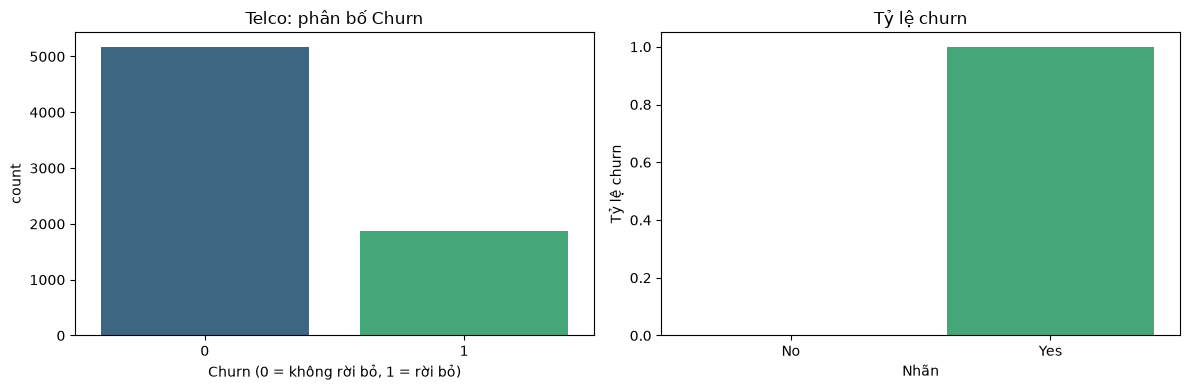

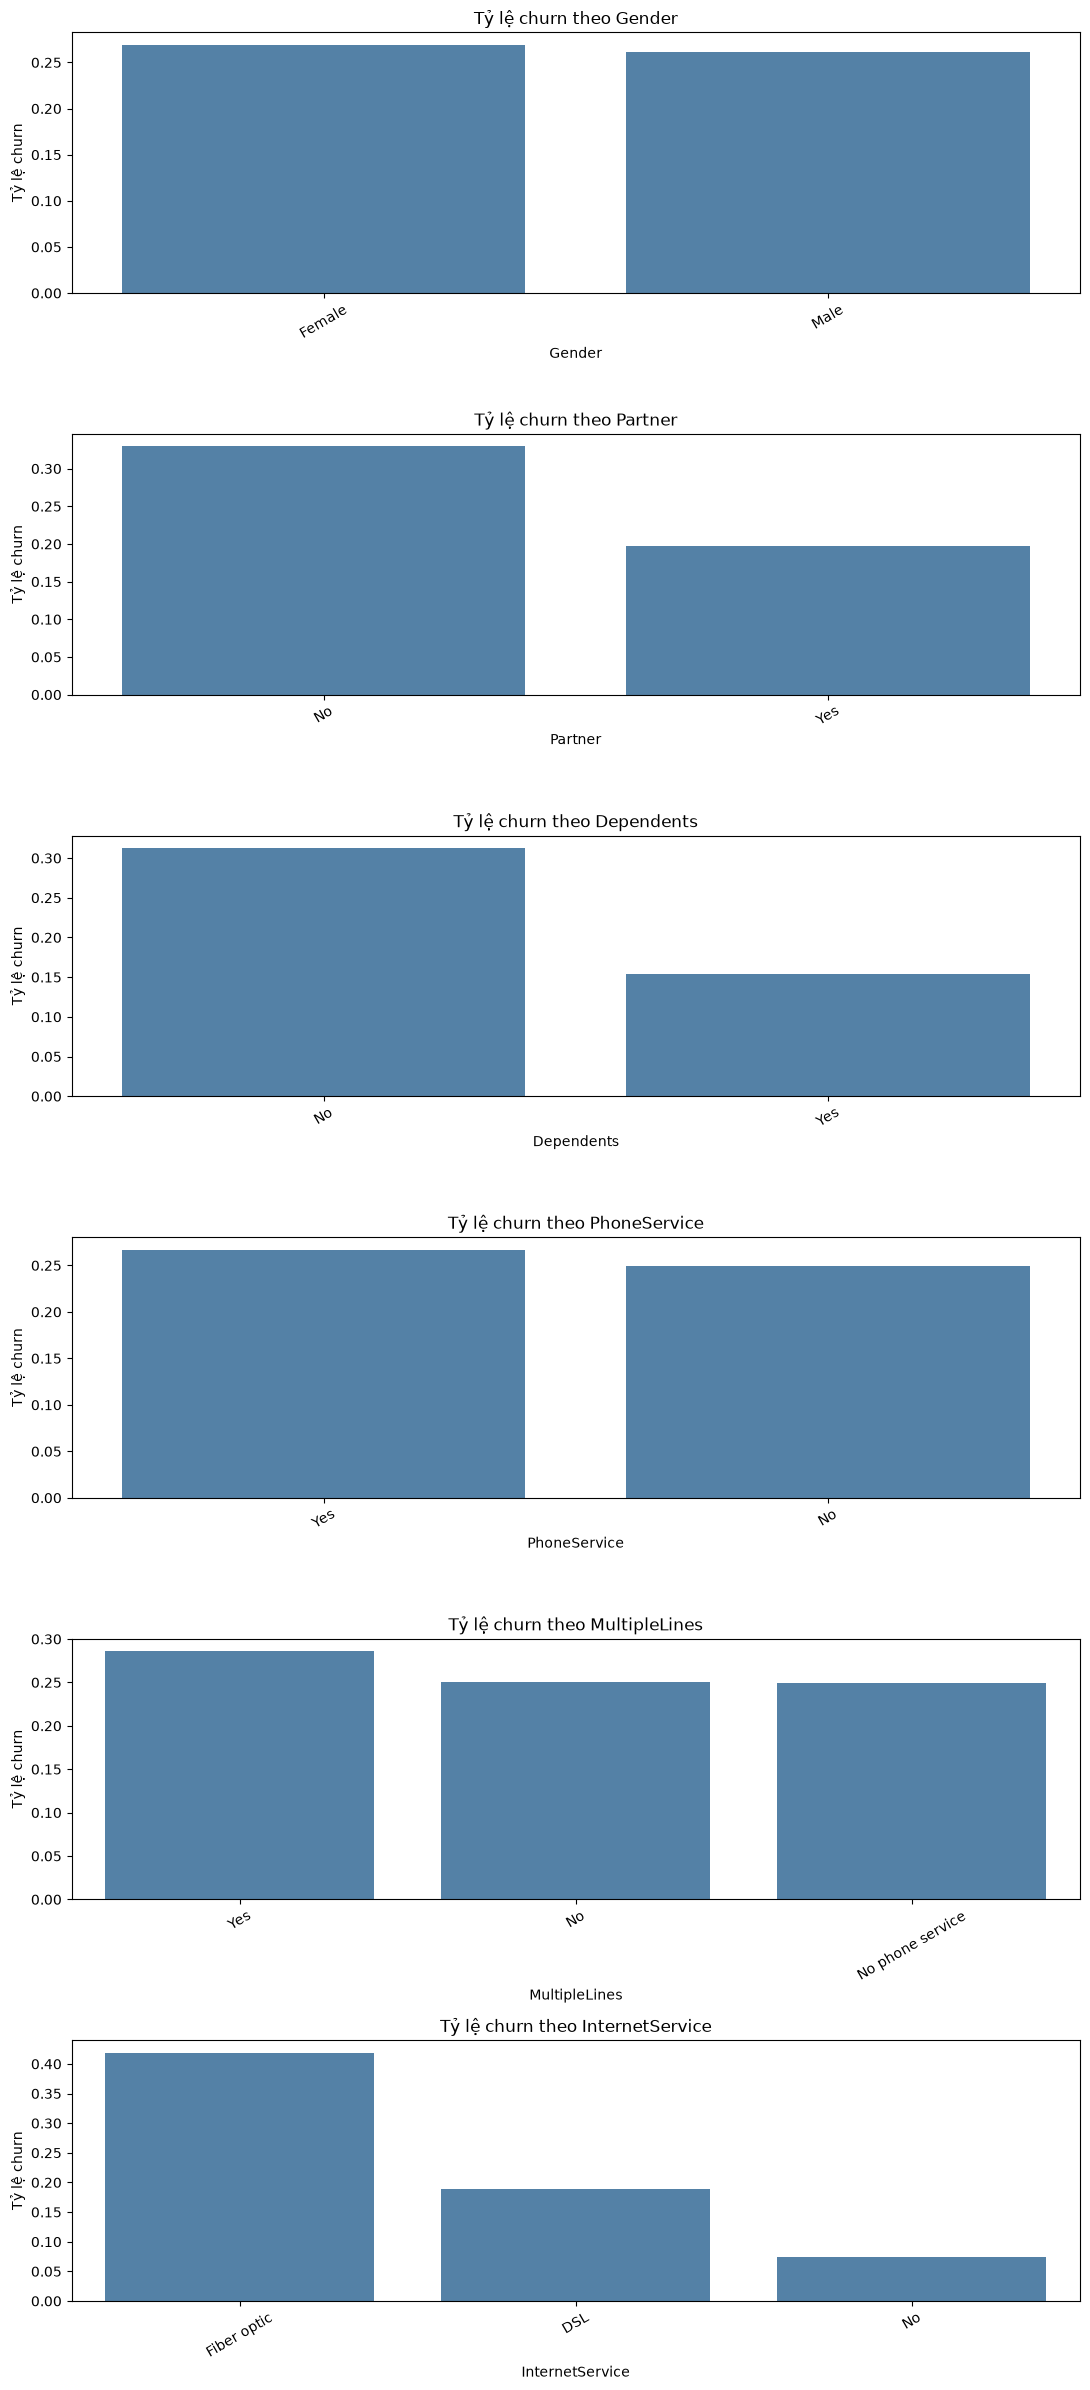

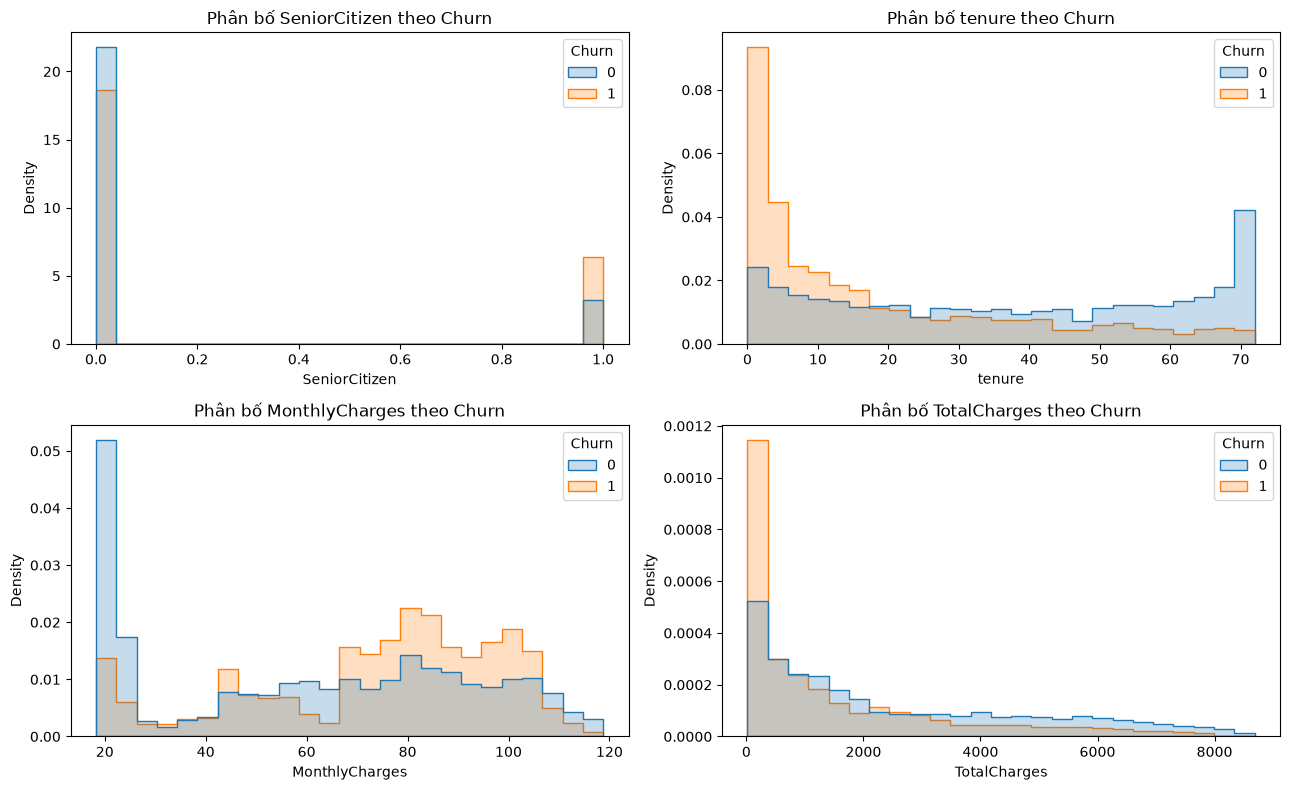

In [27]:
plot_eda(telco, 'Telco')

Telco | Logistic Regression: hoàn tất
Telco | Decision Tree: hoàn tất
Telco | kNN: hoàn tất
Telco | Random Forest: hoàn tất
Telco | SVM: hoàn tất


,Bộ dữ liệu,Mô hình,Train rows,Test rows,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (s)
4,Telco,SVM,5634,1409,0.738,0.504,0.789,0.615,0.839,0.048
0,Telco,Logistic Regression,5634,1409,0.738,0.504,0.783,0.614,0.841,0.062
3,Telco,Random Forest,5634,1409,0.768,0.557,0.618,0.586,0.821,0.252
2,Telco,kNN,5634,1409,0.764,0.553,0.575,0.564,0.790,0.033
1,Telco,Decision Tree,5634,1409,0.732,0.495,0.487,0.491,0.654,0.067


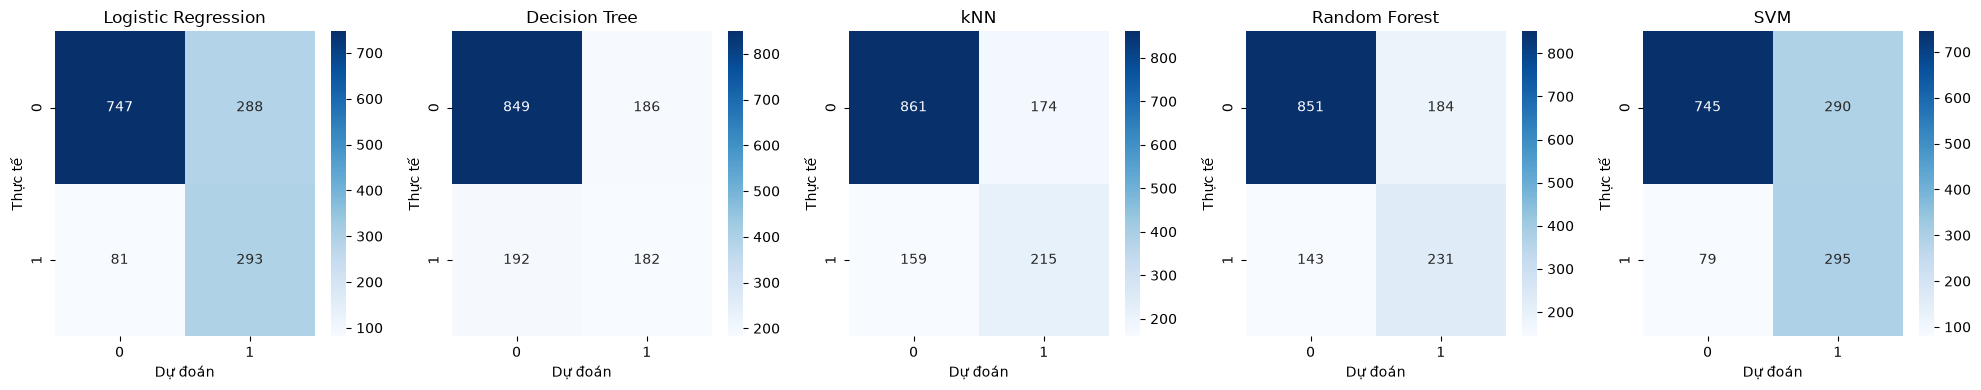

In [28]:
telco_results, telco_y_test, telco_predictions = run_models(telco, 'Telco')
display(telco_results.sort_values('F1', ascending=False).round(3))

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (model_name, y_pred) in zip(axes, telco_predictions.items()):
    sns.heatmap(confusion_matrix(telco_y_test, y_pred, labels=[0, 1]), annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(model_name)
    ax.set_xlabel('Dự đoán')
    ax.set_ylabel('Thực tế')
plt.tight_layout()
plt.show()

# Bộ dữ liệu 2 — Behavioral training (`customer_churn_dataset-training-master1.csv`)

## Outline
1. Đọc và làm sạch riêng file training; loại dòng thiếu nhãn nếu có.
2. Kiểm tra cấu trúc, giá trị thiếu/trùng và phân bố Churn.
3. Khám phá phân bố biến phân loại và biến số.
4. Chia riêng bộ training thành train/test theo tỷ lệ 80/20; huấn luyện 5 mô hình.
5. So sánh metric và confusion matrix.

In [29]:
behavioral_train_raw = pd.read_csv(DATA_DIR / 'customer_churn_dataset-training-master1.csv', low_memory=False)
behavioral_train = clean_dataset(behavioral_train_raw, 'Behavioral training')
inspect_dataset(behavioral_train, 'Behavioral training')

Behavioral training: loại 1 dòng không có nhãn Churn hợp lệ; bỏ cột ID: ['CustomerID'].
Behavioral training: 440,832 dòng x 11 cột


,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1
1,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1
2,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1
3,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1
4,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1


,Kiểu dữ liệu
Age,float64
Gender,str
Tenure,float64
Usage Frequency,float64
Support Calls,float64
Payment Delay,float64
Subscription Type,str
Contract Length,str
Total Spend,float64
Last Interaction,float64


,Giá trị thiếu
Age,0
Gender,0
Tenure,0
Usage Frequency,0
Support Calls,0
Payment Delay,0
Subscription Type,0
Contract Length,0
Total Spend,0
Last Interaction,0


Số dòng trùng hoàn toàn: 0


,Số lượng
Churn,
1,249999
0,190833


,Tỷ lệ
Churn,
1,0.567107
0,0.432893


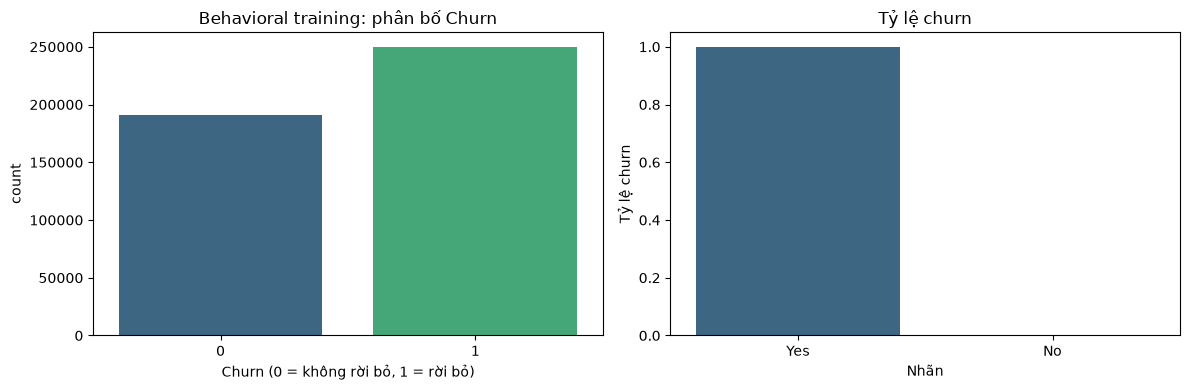

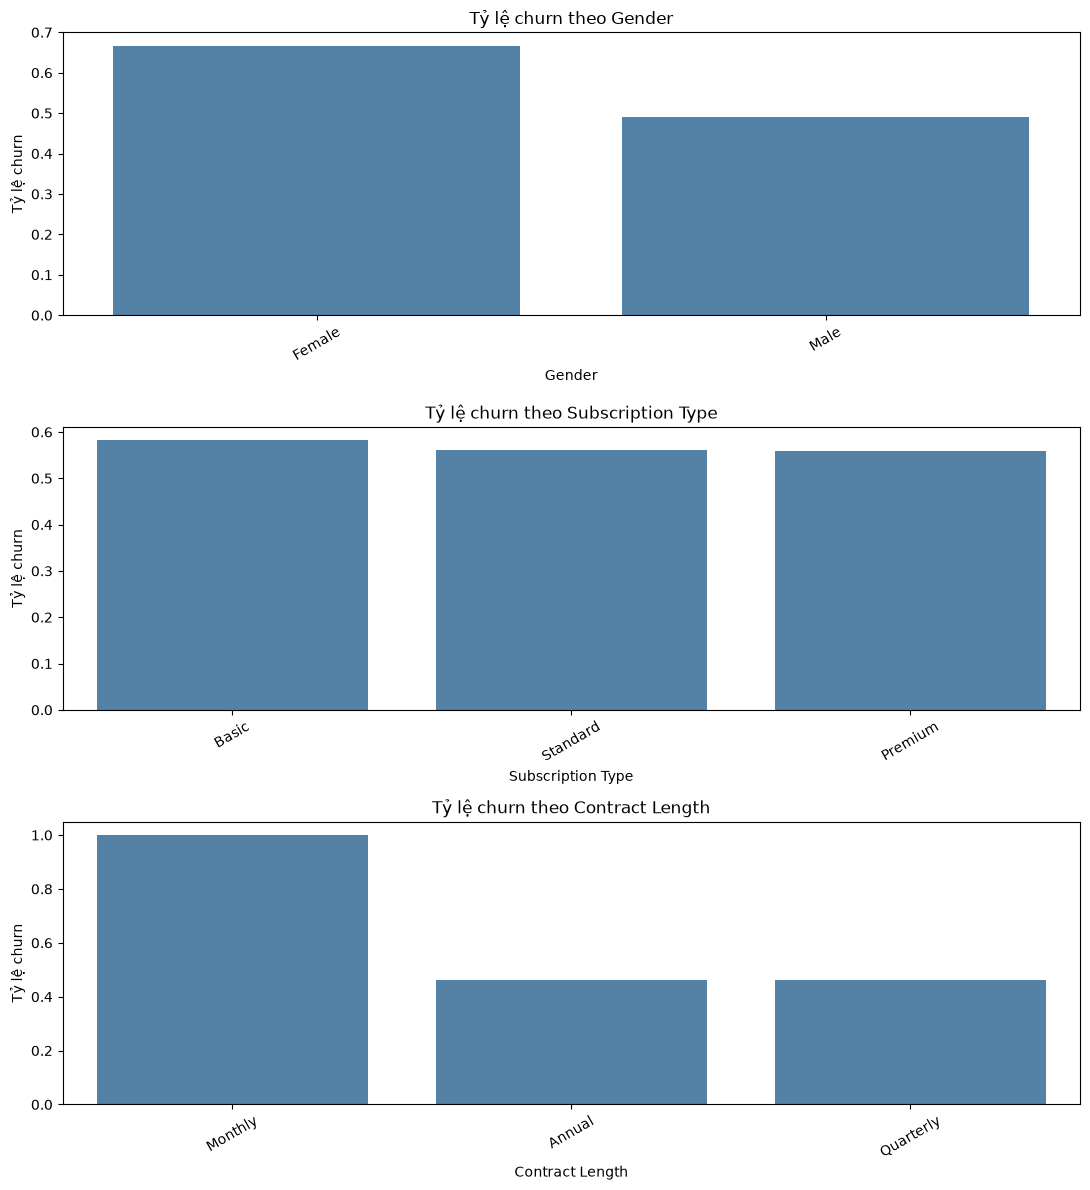

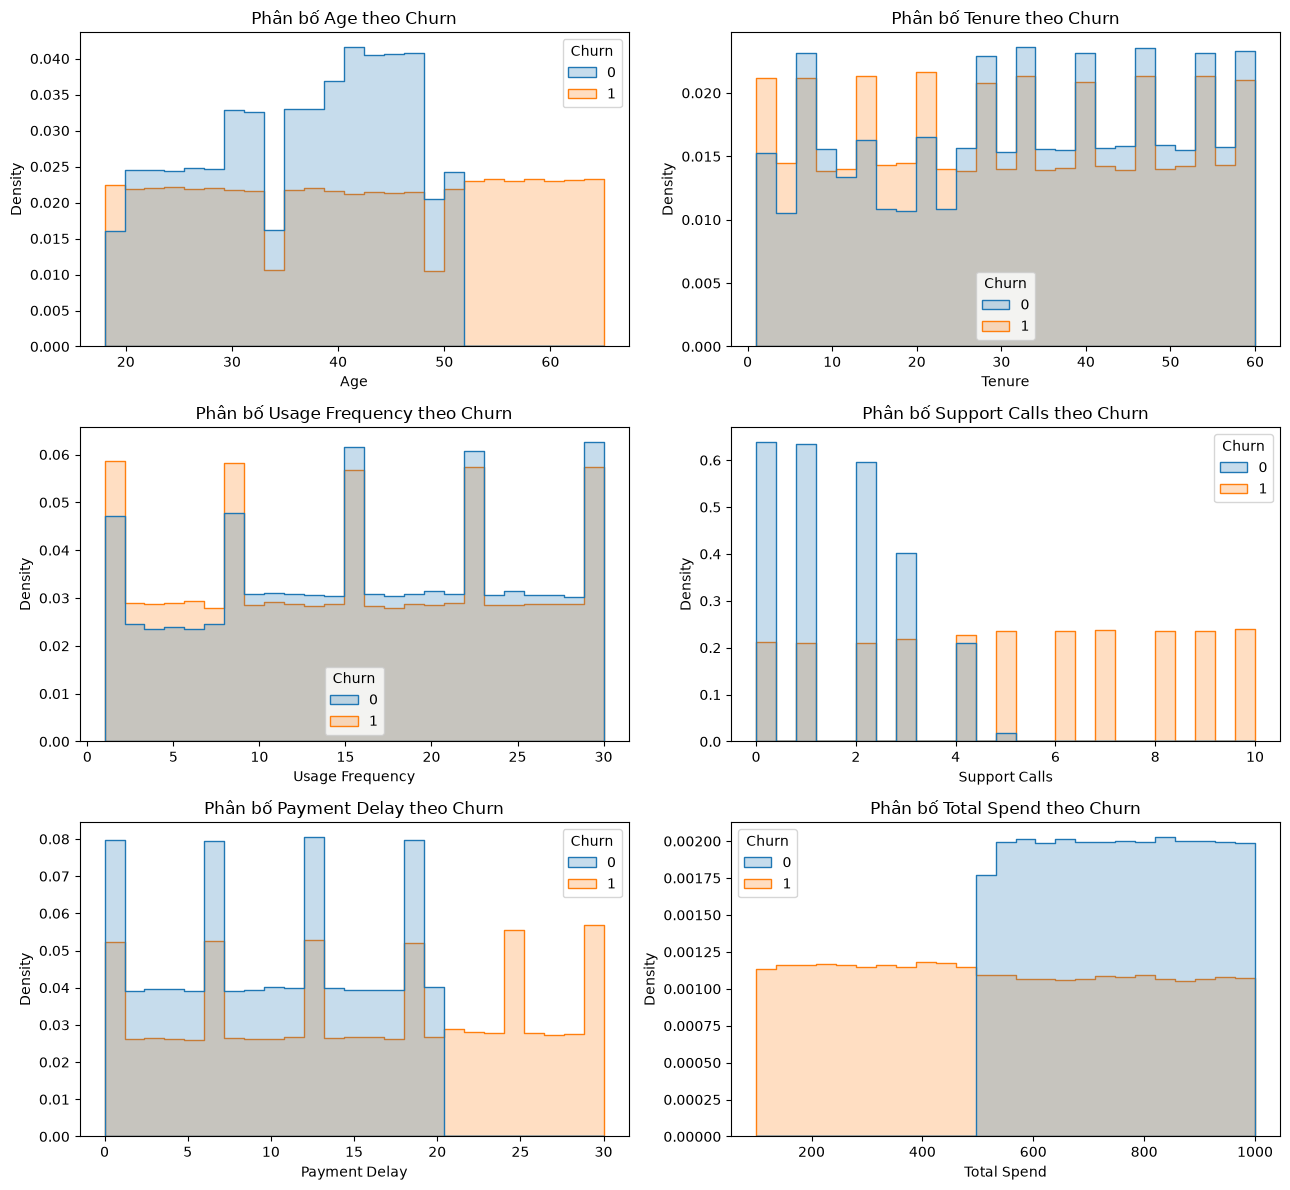

In [30]:
plot_eda(behavioral_train, 'Behavioral training')

Behavioral training | Logistic Regression: hoàn tất
Behavioral training | Decision Tree: hoàn tất
Behavioral training | kNN: hoàn tất
Behavioral training | Random Forest: hoàn tất
Behavioral training | SVM: hoàn tất


,Bộ dữ liệu,Mô hình,Train rows,Test rows,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (s)
1,Behavioral training,Decision Tree,30000,5000,0.999,0.999,0.999,0.999,0.999,0.102
3,Behavioral training,Random Forest,30000,5000,0.994,1.000,0.990,0.995,1.000,0.480
2,Behavioral training,kNN,30000,5000,0.931,0.997,0.882,0.936,0.979,0.125
0,Behavioral training,Logistic Regression,30000,5000,0.895,0.947,0.862,0.903,0.961,0.097
4,Behavioral training,SVM,30000,5000,0.894,0.949,0.859,0.902,0.961,0.082


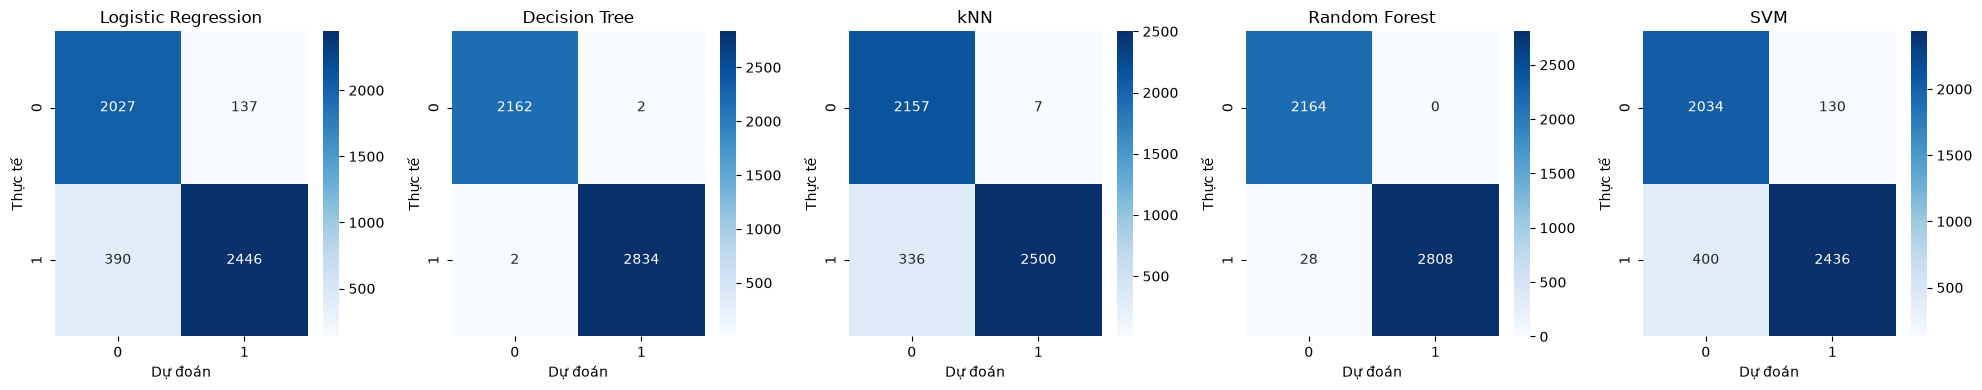

In [31]:
behavioral_train_results, behavioral_train_y_test, behavioral_train_predictions = run_models(
    behavioral_train, 'Behavioral training'
)
display(behavioral_train_results.sort_values('F1', ascending=False).round(3))

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (model_name, y_pred) in zip(axes, behavioral_train_predictions.items()):
    sns.heatmap(confusion_matrix(behavioral_train_y_test, y_pred, labels=[0, 1]), annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(model_name)
    ax.set_xlabel('Dự đoán')
    ax.set_ylabel('Thực tế')
plt.tight_layout()
plt.show()

# Bộ dữ liệu 3 — Behavioral testing (`customer_churn_dataset-testing-master2.csv`)

## Outline
1. Đọc và làm sạch riêng file testing.
2. Kiểm tra cấu trúc, giá trị thiếu/trùng và phân bố Churn.
3. Khám phá phân bố biến phân loại và biến số.
4. Chia riêng bộ testing thành train/test theo tỷ lệ 80/20; huấn luyện 5 mô hình.
5. So sánh metric và confusion matrix.

Trong notebook này file testing được xem là một bộ dữ liệu riêng theo yêu cầu, không dùng để đánh giá mô hình đã huấn luyện từ file master1.

In [32]:
behavioral_test_raw = pd.read_csv(DATA_DIR / 'customer_churn_dataset-testing-master2.csv', low_memory=False)
behavioral_test = clean_dataset(behavioral_test_raw, 'Behavioral testing')
inspect_dataset(behavioral_test, 'Behavioral testing')

Behavioral testing: loại 0 dòng không có nhãn Churn hợp lệ; bỏ cột ID: ['CustomerID'].
Behavioral testing: 64,374 dòng x 11 cột


,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,53,Female,58,24,9,2,Standard,Annual,533,18,0


,Kiểu dữ liệu
Age,int64
Gender,str
Tenure,int64
Usage Frequency,int64
Support Calls,int64
Payment Delay,int64
Subscription Type,str
Contract Length,str
Total Spend,int64
Last Interaction,int64


,Giá trị thiếu
Age,0
Gender,0
Tenure,0
Usage Frequency,0
Support Calls,0
Payment Delay,0
Subscription Type,0
Contract Length,0
Total Spend,0
Last Interaction,0


Số dòng trùng hoàn toàn: 0


,Số lượng
Churn,
0,33881
1,30493


,Tỷ lệ
Churn,
0,0.526315
1,0.473685


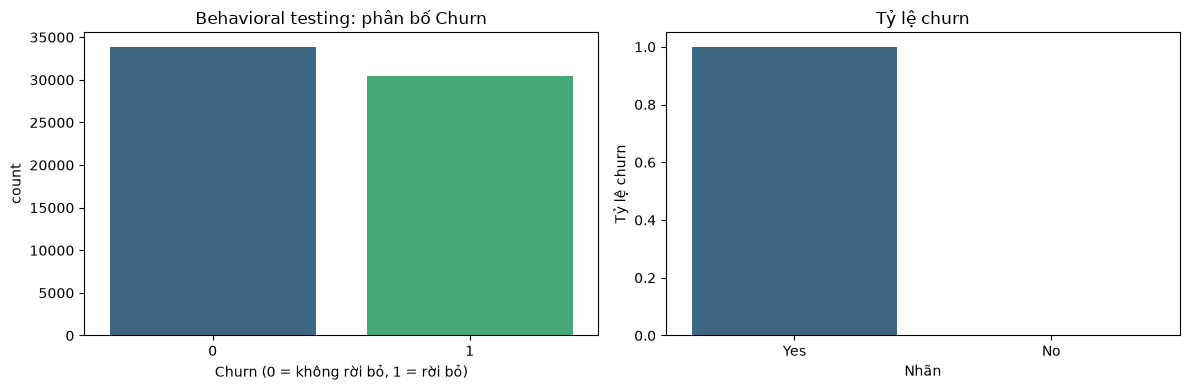

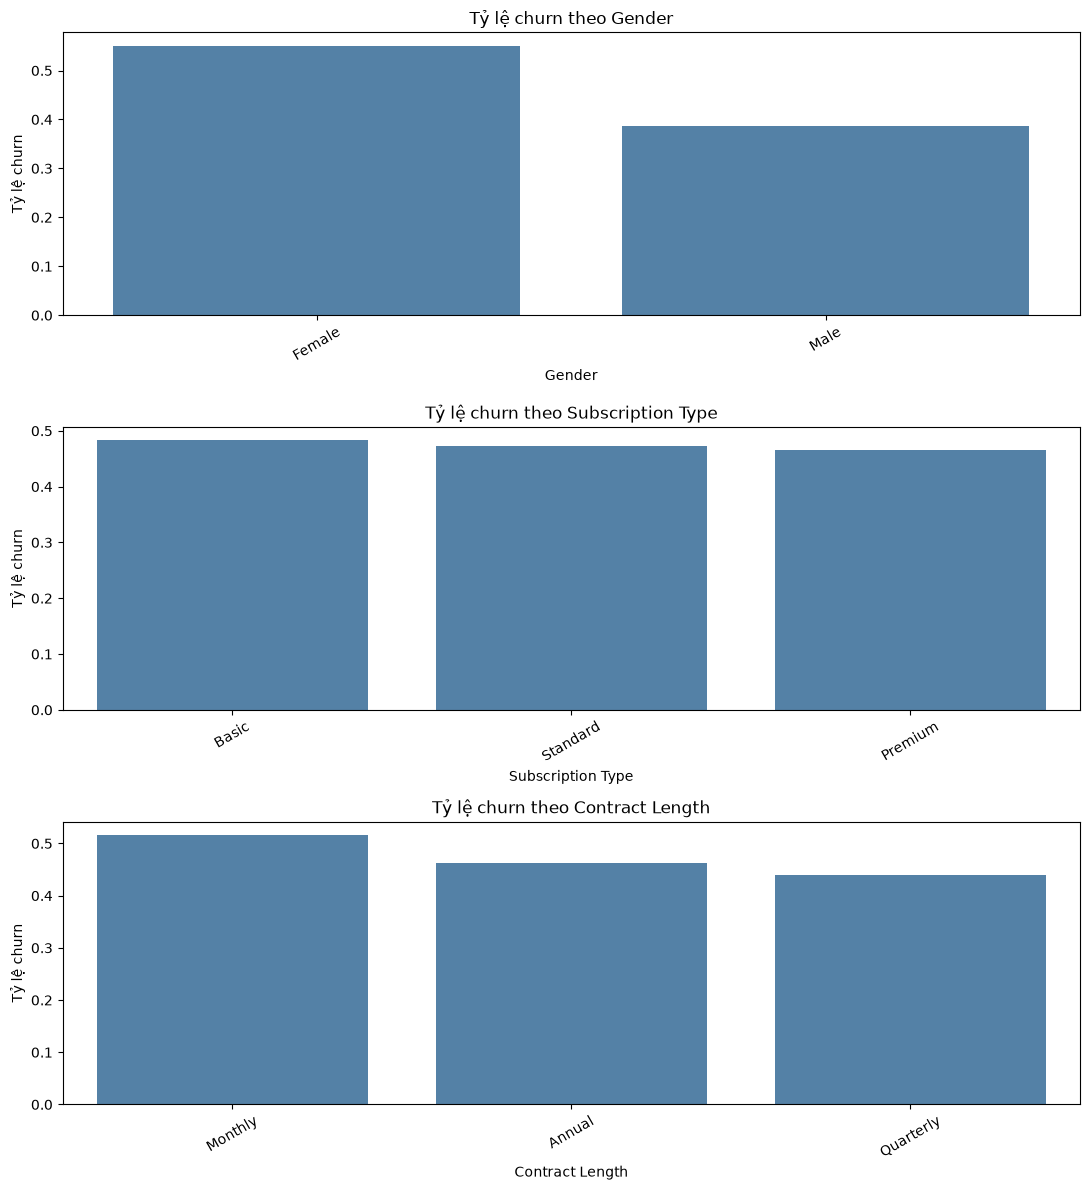

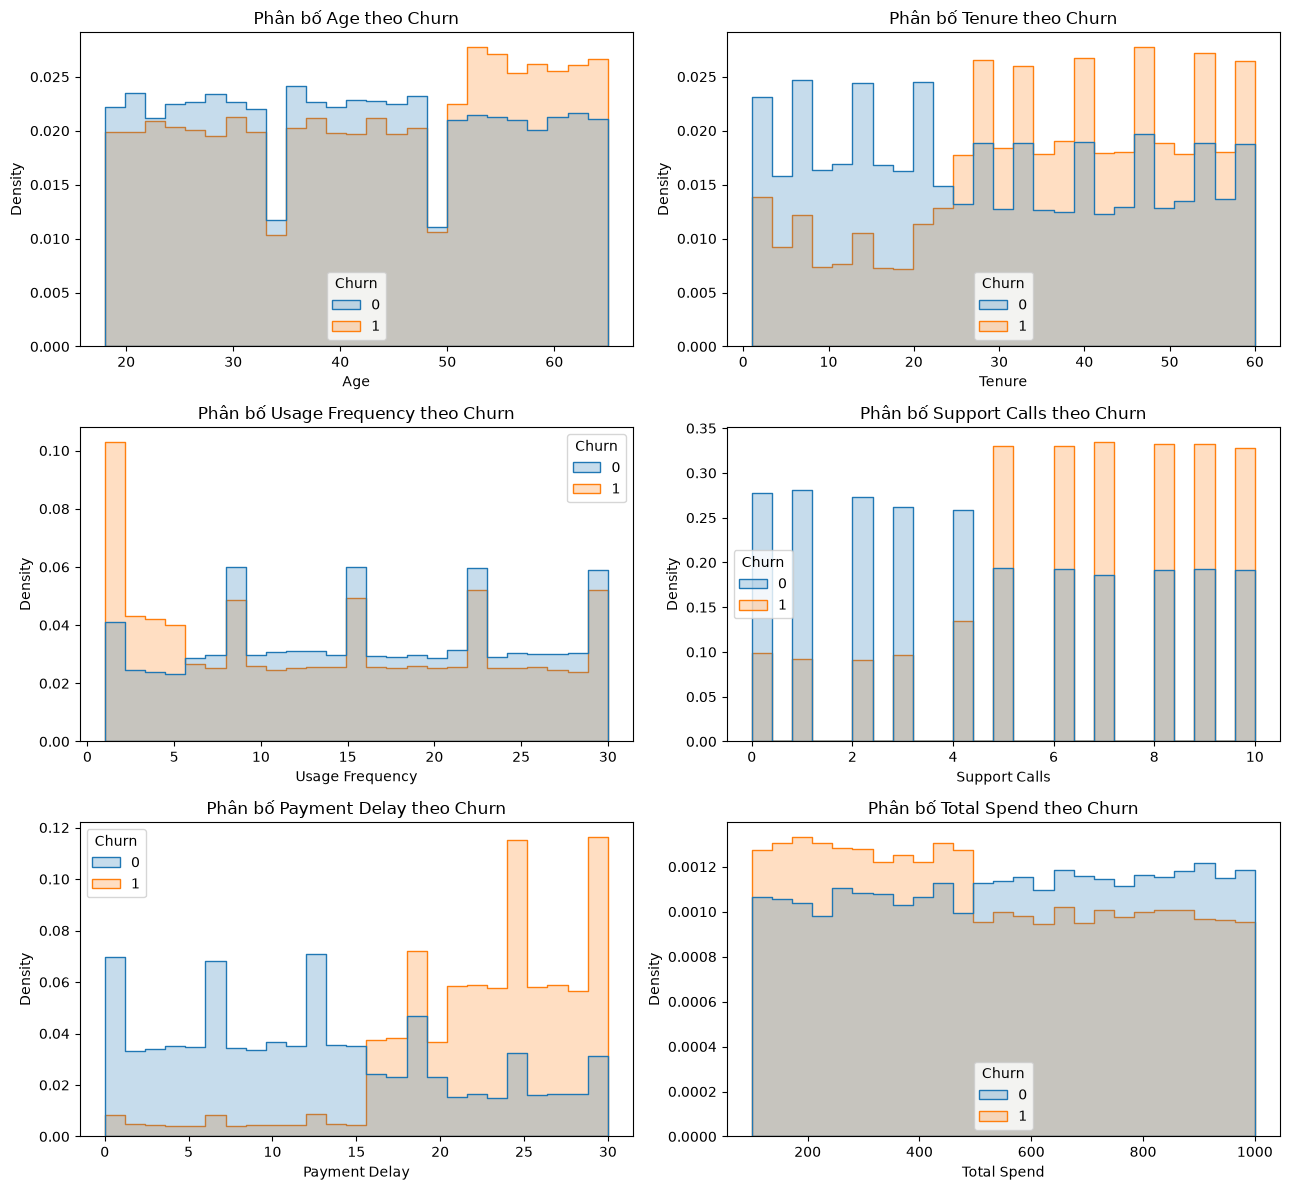

In [33]:
plot_eda(behavioral_test, 'Behavioral testing')

Behavioral testing | Logistic Regression: hoàn tất
Behavioral testing | Decision Tree: hoàn tất
Behavioral testing | kNN: hoàn tất
Behavioral testing | Random Forest: hoàn tất
Behavioral testing | SVM: hoàn tất


,Bộ dữ liệu,Mô hình,Train rows,Test rows,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (s)
3,Behavioral testing,Random Forest,30000,5000,0.998,1.000,0.997,0.998,1.000,0.419
1,Behavioral testing,Decision Tree,30000,5000,0.996,0.994,0.998,0.996,0.996,0.086
2,Behavioral testing,kNN,30000,5000,0.900,0.870,0.928,0.898,0.961,0.109
0,Behavioral testing,Logistic Regression,30000,5000,0.832,0.807,0.848,0.827,0.905,0.057
4,Behavioral testing,SVM,30000,5000,0.830,0.802,0.852,0.826,0.905,0.063


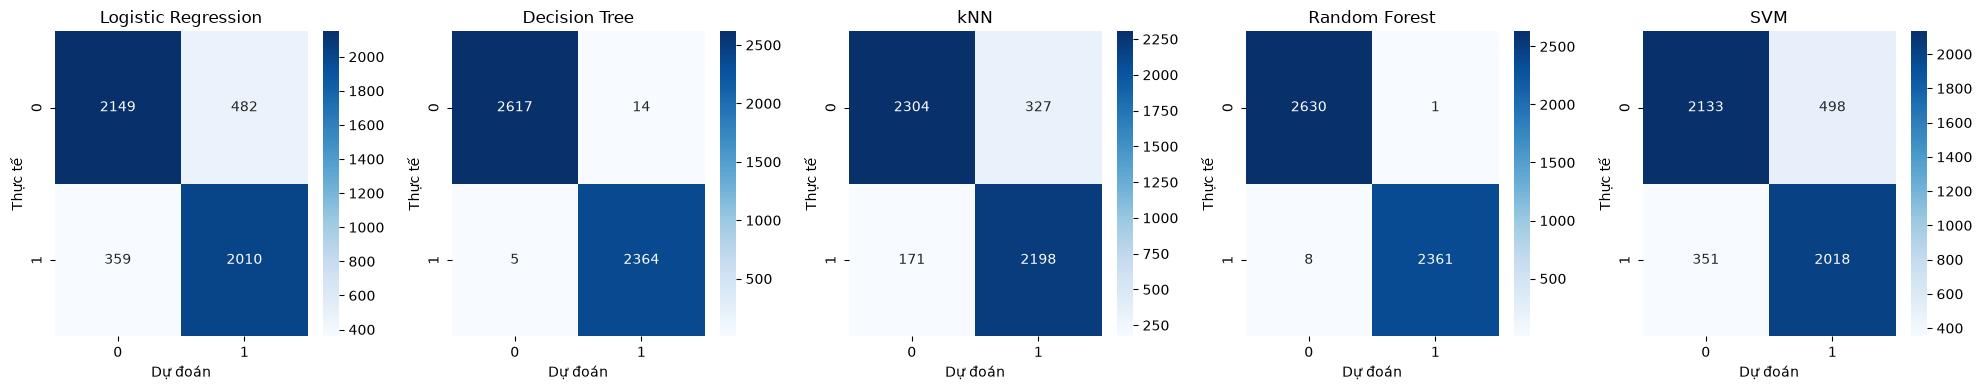

In [34]:
behavioral_test_results, behavioral_test_y_test, behavioral_test_predictions = run_models(
    behavioral_test, 'Behavioral testing'
)
display(behavioral_test_results.sort_values('F1', ascending=False).round(3))

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (model_name, y_pred) in zip(axes, behavioral_test_predictions.items()):
    sns.heatmap(confusion_matrix(behavioral_test_y_test, y_pred, labels=[0, 1]), annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(model_name)
    ax.set_xlabel('Dự đoán')
    ax.set_ylabel('Thực tế')
plt.tight_layout()
plt.show()

# So sánh tổng hợp 3 bộ dữ liệu

Tổng hợp 15 kết quả (3 bộ dữ liệu × 5 mô hình). So sánh 5 mô hình **trong cùng một bộ** là trực tiếp; so sánh điểm số **giữa các bộ** chỉ mang tính tham khảo vì schema và phân phối khác nhau.

In [35]:
all_results = pd.concat(
    [telco_results, behavioral_train_results, behavioral_test_results],
    ignore_index=True,
)
comparison = all_results.sort_values(['Bộ dữ liệu', 'F1'], ascending=[True, False]).reset_index(drop=True)
display(comparison.round(3))

comparison_pivot = comparison.pivot(index='Mô hình', columns='Bộ dữ liệu', values='F1')
print('F1-score theo mô hình và bộ dữ liệu:')
display(comparison_pivot.round(3))

,Bộ dữ liệu,Mô hình,Train rows,Test rows,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (s)
0,Behavioral testing,Random Forest,30000,5000,0.998,1.000,0.997,0.998,1.000,0.419
1,Behavioral testing,Decision Tree,30000,5000,0.996,0.994,0.998,0.996,0.996,0.086
2,Behavioral testing,kNN,30000,5000,0.900,0.870,0.928,0.898,0.961,0.109
3,Behavioral testing,Logistic Regression,30000,5000,0.832,0.807,0.848,0.827,0.905,0.057
4,Behavioral testing,SVM,30000,5000,0.830,0.802,0.852,0.826,0.905,0.063
5,Behavioral training,Decision Tree,30000,5000,0.999,0.999,0.999,0.999,0.999,0.102
6,Behavioral training,Random Forest,30000,5000,0.994,1.000,0.990,0.995,1.000,0.480
7,Behavioral training,kNN,30000,5000,0.931,0.997,0.882,0.936,0.979,0.125
8,Behavioral training,Logistic Regression,30000,5000,0.895,0.947,0.862,0.903,0.961,0.097
9,Behavioral training,SVM,30000,5000,0.894,0.949,0.859,0.902,0.961,0.082


F1-score theo mô hình và bộ dữ liệu:


Bộ dữ liệu,Behavioral testing,Behavioral training,Telco
Mô hình,,,
Decision Tree,0.996,0.999,0.491
Logistic Regression,0.827,0.903,0.614
Random Forest,0.998,0.995,0.586
SVM,0.826,0.902,0.615
kNN,0.898,0.936,0.564


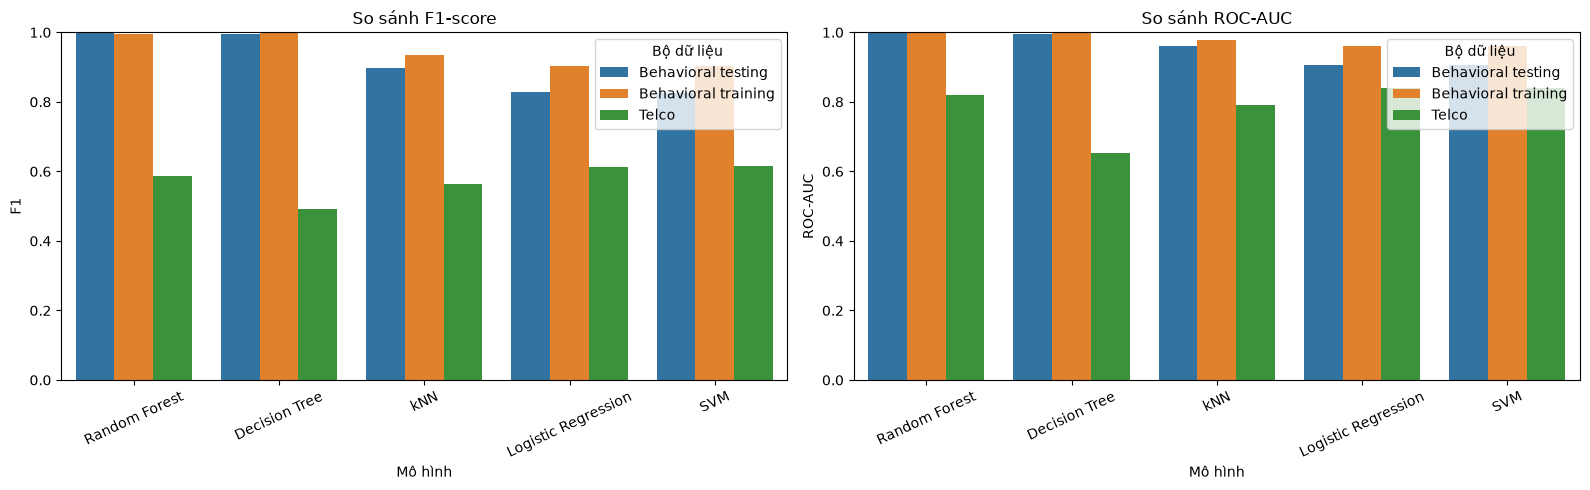

Mô hình F1 cao nhất trong từng bộ dữ liệu:


,Bộ dữ liệu,Mô hình,F1,ROC-AUC,Accuracy
0,Behavioral testing,Random Forest,0.998,1.000,0.998
1,Behavioral training,Decision Tree,0.999,0.999,0.999
2,Telco,SVM,0.615,0.839,0.738


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=comparison, x='Mô hình', y='F1', hue='Bộ dữ liệu', ax=axes[0])
axes[0].set_title('So sánh F1-score')
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis='x', rotation=25)
sns.barplot(data=comparison, x='Mô hình', y='ROC-AUC', hue='Bộ dữ liệu', ax=axes[1])
axes[1].set_title('So sánh ROC-AUC')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

print('Mô hình F1 cao nhất trong từng bộ dữ liệu:')
best_models = comparison.loc[comparison.groupby('Bộ dữ liệu')['F1'].idxmax(), ['Bộ dữ liệu', 'Mô hình', 'F1', 'ROC-AUC', 'Accuracy']]
display(best_models.reset_index(drop=True).round(3))

## Ghi chú kết quả

- Mỗi bộ dữ liệu dùng phép chia phân tầng 80/20 riêng, `random_state=42`.
- Dữ liệu lớn được lấy mẫu phân tầng sau khi chia; không làm thay đổi tỷ lệ nhãn đáng kể.
- Hãy xem Precision, Recall, F1 và ROC-AUC cùng nhau; Accuracy riêng lẻ có thể gây hiểu nhầm khi nhãn mất cân bằng.
- Nếu muốn chạy toàn bộ dữ liệu, đặt `MAX_TRAIN_ROWS = None` và `MAX_TEST_ROWS = None` ở cell cấu hình; quá trình sẽ tốn thời gian/bộ nhớ hơn.